# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170419          # <-- your full roll number
NAME = "Shubhas kumar sah"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170419   Name: Shubhas kumar sah   Fingerprint: 149ECC06   Tickets: 16

Ticket_ID                                                                          Ticket_Text
      T01                    Python failed to open since yesterday. Is there another solution?
      T02                                          The state-of-the-art lab (Lab-3) is closed.
      T03                 The student portal was working yesterday. I don't know what changed.
      T04                                                        Why isn't the portal opening?
      T05                       The printer was working yesterday. I have tried several times!
      T06                                 The password keeps asking for login. This is urgent.
      T07 I was locked out of the MATLAB when I use mobile hotspot. Is there another solution?
      T08    I cannot access the student portal during the lab. The same problem occurs again.
      T09               I couldn't connect to the server

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Your code


import pandas as pd
import string

# Use the dataset generated in cell 4
raw_tickets = df["Ticket_Text"].tolist()

rows = []
all_tokens = []
all_punctuation = []
all_stopwords = []
all_final_tokens = []

for ticket_id, ticket in zip(df["Ticket_ID"], raw_tickets):
    result = process_ticket(ticket)

    tokens = result["tokens"]
    punctuation = result["punct"]
    stops = result["stops"]
    final_tokens = result["final"]
    sentences = result["sentences"]

    all_tokens.extend(tokens)
    all_punctuation.extend(punctuation)
    all_stopwords.extend(stops)
    all_final_tokens.extend(final_tokens)

    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(sentences),
        "Tokens": len(tokens),
        "Punctuation": len(punctuation),
        "Stopwords": len(stops),
        "Unique_Tokens": len(set(tokens)),
        "Final_Tokens": len(final_tokens)
    })

result_table = pd.DataFrame(rows)

# Total row for count-based columns
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": result_table["Sentences"].sum(),
    "Tokens": result_table["Tokens"].sum(),
    "Punctuation": result_table["Punctuation"].sum(),
    "Stopwords": result_table["Stopwords"].sum(),
    "Unique_Tokens": result_table["Unique_Tokens"].sum(),
    "Final_Tokens": result_table["Final_Tokens"].sum()
}

result_table = pd.concat(
    [result_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(result_table)

# Actual token details for one selected ticket
selected_index = 0
selected_ticket = raw_tickets[selected_index]
selected_result = process_ticket(selected_ticket)

print("Selected Ticket ID:", df["Ticket_ID"].iloc[selected_index])
print("Raw ticket:", selected_ticket)
print("Sentences:", selected_result["sentences"])
print("Tokens:", selected_result["tokens"])
print("Punctuation tokens:", selected_result["punct"])
print("Stopwords:", selected_result["stops"])
print("Final tokens:", selected_result["final"])



,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,12,2,3,12,7
1,T02,1,9,3,2,9,4
2,T03,2,14,2,5,13,7
3,T04,1,7,1,3,7,3
4,T05,2,12,2,4,12,6
5,T06,2,11,2,4,10,5
6,T07,2,18,2,9,17,7
7,T08,2,17,2,9,14,6
8,T09,2,15,2,5,13,8
9,T10,2,20,2,9,16,9


Selected Ticket ID: T01
Raw ticket: Python failed to open since yesterday. Is there another solution?
Sentences: ['Python failed to open since yesterday.', 'Is there another solution?']
Tokens: ['python', 'failed', 'to', 'open', 'since', 'yesterday', '.', 'is', 'there', 'another', 'solution', '?']
Punctuation tokens: ['.', '?']
Stopwords: ['to', 'is', 'there']
Final tokens: ['python', 'failed', 'open', 'since', 'yesterday', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*Tokens like n't, 's, and ca come from contractions such as isn't and can't. They are split by word_tokenize() and remain if they are not removed during preprocessing.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [14]:

import re

# TEST_LINES are already provided in your notebook

# Preserve decimals, versions and comma-separated numbers
number_pattern = r"\b\d{1,3}(?:,\d{3})+(?:\.\d+)?\b|\b\d+(?:\.\d+)*\b"

# Match the phone formats used in TEST_LINES
phone_pattern = (
    r"(?<!\w)(?:\+\d{1,3}[-.\s]?)?"
    r"(?:\d{5}[-.\s]?\d{5}|\d{4}[-.\s]?\d{3}[-.\s]?\d{4})"
    r"(?!\w)"
)

for line in TEST_LINES:
    print("Numbers:", re.findall(number_pattern, line))
    print("Redacted:", re.sub(phone_pattern, "<PHONE>", line))


for line in TEST_LINES:
    print("\nText:", line)
    for name, pattern in patterns.items():
        print(name, ":", re.findall(pattern, line))

# Replacement patterns
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://[^\s<>\"']+|www\.[^\s<>\"']+"
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[-.\s]?)?(?:\(?\d{3,5}\)?[-.\s]?)\d{3,4}[-.\s]?\d{4}(?!\w)"

def replace_patterns(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nREPLACEMENT ON TEST_LINES")
for line in TEST_LINES:
    print(replace_patterns(line))

# Get raw tickets from the generated DataFrame
raw_tickets = df["Ticket_Text"].tolist()

print("\nREPLACEMENT ON RAW TICKETS")
for ticket in raw_tickets:
    print(replace_patterns(ticket))



Numbers: []
Redacted: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
Redacted: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Numbers: ['5.30']
Redacted: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words longer than 5 letters : ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers : []
Capitalized words : ['Mail']
Words starting with a vowel : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words longer than 5 letters : ['Version']
Numbers : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Some capitalized words, such as Mail, Call, and The, are capitalized only because they begin a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [15]:
# Your code


import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Use TEST_LINES already defined in your notebook.
# If it is not defined, run the cell that contains TEST_LINES first.

pattern = (
    r"https?://[^\s<>\"']*[^\W_.,;:!?\"')\]]|www\.[^\s<>\"']*[^\W_.,;:!?\"')\]]|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"(?<!\w)(?:\+\d{1,3}[-.\s]?)?"
    r"(?:\d{5}[-.\s]?\d{5}|\d{4}[-.\s]?\d{3}[-.\s]?\d{4})(?!\w)|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"
    r"[A-Za-z]+(?:'[A-Za-z]+)+|"
    r"\d+(?:\.\d+)?|"
    r"[A-Za-z]+|"
    r"[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Compare TEST_LINES
for line in TEST_LINES:
    print("\nText:", line)
    print("Custom:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

# Compare generated tickets
different_count = 0

for ticket_id, ticket in zip(df["Ticket_ID"], raw_tickets):
    custom = my_tokenize(ticket)
    standard = word_tokenize(ticket)

    if custom != standard:
        different_count += 1
        print(f"\n{ticket_id}: {ticket}")
        print("Custom:", custom)
        print("Standard:", standard)

print("\nTickets tokenized differently:", different_count)
print("Total tickets:", len(raw_tickets))




Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['Th

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*My custom tokenizer differs from word_tokenize() because it preserves contractions like isn't, hyphenated words like state-of-the-art, and versions like 2.0.1 as single tokens, whereas word_tokenize() may split them into multiple tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [16]:
# Your code


from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex_stemmer = RegexpStemmer("ing$")
lemmatizer = WordNetLemmatizer()

# Unique final tokens from your own dataset
unique_words = sorted(set(all_final_tokens))

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

tagged_words = pos_tag(unique_words)
rows = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regex_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=pos)

    if len({p, l, r, lemma}) > 1:
        rows.append({
            "Word": word,
            "POS": tag,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet Lemma": lemma
        })

comparison = pd.DataFrame(rows)
display(comparison)

print("Regexp suffix: ing$")
print("Justification: the dataset contains words ending in 'ing'.")

# Find possible over-stemming examples
print("\nPossible over-stemming examples (Lancaster):")
if not comparison.empty:
    candidates = comparison[
        (comparison["Word"].str.len() >= 5) &
        (comparison["Lancaster"].str.len() <= 3) &
        (comparison["Lancaster"] != comparison["Word"])
    ]
    display(candidates[["Word", "Lancaster"]].head(5))

# Find examples where the regex rule does not remove other suffixes
print("\nPossible under-stemming examples (Regexp):")
if not comparison.empty:
    candidates = comparison[
        comparison["Word"].str.endswith(("ed", "s", "er", "ly")) &
        (comparison["Regexp"] == comparison["Word"])
    ]
    display(candidates[["Word", "Regexp"]].head(5))

print("Reason: words such as working, uploading and reinstalling occur in the dataset.")


,Word,POS,Porter,Lancaster,Regexp,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,assignment,NN,assign,assign,assignment,assignment
2,changed,VBD,chang,chang,changed,change
3,closed,JJ,close,clos,closed,closed
4,deadline,VB,deadlin,deadlin,deadline,deadline
5,details,NNS,detail,detail,details,detail
6,failed,VBD,fail,fail,failed,fail
7,https,JJ,http,https,https,https
8,keeps,NNS,keep,keep,keeps,keep
9,latest,JJS,latest,latest,latest,late


Regexp suffix: ing$
Justification: the dataset contains words ending in 'ing'.

Possible over-stemming examples (Lancaster):


,Word,Lancaster
14,occurs,occ
16,opening,op
23,running,run
25,several,sev
30,times,tim



Possible under-stemming examples (Regexp):


,Word,Regexp
0,another,another
2,changed,changed
3,closed,closed
5,details,details
6,failed,failed


Reason: words such as working, uploading and reinstalling occur in the dataset.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*Over-stemming: Lancaster stemming can remove too much of a word, producing a stem that loses its original meaning. Use an example from the printed candidate table.



Under-stemming: The Regexp Stemmer leaves worked unchanged because its rule removes only ing, not ed.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,199,94,0.4724
1,S2 - No punctuation,168,88,0.5238
2,S3 - Final tokens,95,63,0.6632
3,S4 - Porter stemmed,95,62,0.6526


Top 10 words in S1: [('.', 24), ('the', 17), ('i', 11), ('is', 9), ('yesterday', 4), ("n't", 4), ('to', 3), ('?', 3), ('portal', 3), ('was', 3)]
Top 10 words in S3: [('yesterday', 4), ("n't", 4), ('portal', 3), ('working', 3), ('use', 3), ('please', 3), ('python', 2), ('since', 2), ('another', 2), ('solution', 2)]


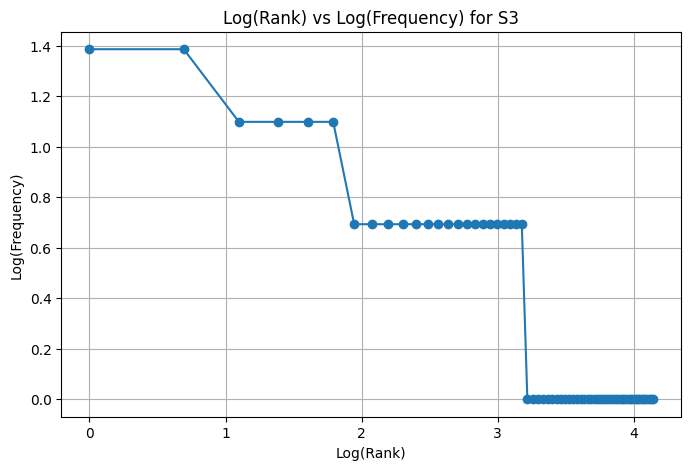

Top 5 bigrams in S1: [(('.', 'i'), 8), (('yesterday', '.'), 4), (('.', 'the'), 4), (('.', 'please'), 3), (('since', 'yesterday'), 2)]
Top 5 bigrams in S3: [(('since', 'yesterday'), 2), (('another', 'solution'), 2), (('student', 'portal'), 2), (('working', 'yesterday'), 2), (("n't", 'know'), 2)]


In [12]:
# Your code

from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import pandas as pd
import matplotlib.pyplot as plt
import math

# S1: All tokens
S1 = list(all_tokens)

# S2: Remove punctuation
S2 = [t for t in S1 if not is_punct(t)]

# S3: Final tokens after preprocessing
S3 = list(all_final_tokens)

# S4: Porter-stemmed final tokens
porter = PorterStemmer()
S4 = [porter.stem(t) for t in S3]

corpora = {
    "S1 - All tokens": S1,
    "S2 - No punctuation": S2,
    "S3 - Final tokens": S3,
    "S4 - Porter stemmed": S4
}

# Statistics table
rows = []
for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    rows.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

display(pd.DataFrame(rows))

# Top 10 words
print("Top 10 words in S1:", Counter(S1).most_common(10))
print("Top 10 words in S3:", Counter(S3).most_common(10))

# Log(rank) vs log(frequency) for S3
frequencies = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(r) for r in ranks],
    [math.log(f) for f in frequencies],
    marker="o"
)
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams
print("Top 5 bigrams in S1:", Counter(bigrams(S1)).most_common(5))
print("Top 5 bigrams in S3:", Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR changes from S1 to S4 because punctuation and stopwords are removed, and stemming combines related words into common stems. This changes the total and unique token counts, so the TTR changes. The exact change depends on the dataset.